# UNIVERSIDAD DE GUAYAQUIL
## APRENDIZAJE AUTOMÁTICO
### CIENCIAS DE DATOS E INTELIGENCIA ARTIFICIAL
#### Proyecto Primer Parcial

**Integrantes:**
* Ma.Fernanda Campoverde (EDA)
* Damian Díaz (Preprocesamiento)
* Jordy León (Regresión lineal)
* Brenda López (Regresión Logística)
* Andrea Peñafiel (Conclusiones)
* Ludy Rivas (Bono extra)

**Paralelo:** 4-2
**Fecha:** 28/11/2026

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar estilo de gráficos
sns.set_theme(style="whitegrid")

# Cargar el dataset (IMPORTANTE: separado por comas)
df = pd.read_csv('student-mat.csv', sep=',')

# Ver las primeras 5 filas
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


**Estructura del dataset**
* El dataset contiene **395 filas** (estudiantes) y **33 columnas**.
* La mayoría de las variables son de tipo `int64` (enteras) y `object` (categóricas).
* La variable objetivo es **G3** (nota final), que va de 0 a 20.


In [10]:
print("--- INFORMACIÓN ---")
df.info()

print("\n--- ESTADÍSTICAS DESCRIPTIVAS ---")
display(df.describe())

--- INFORMACIÓN ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    ob

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


**Interpretación:**
La nota final (G3) tiene una media de aproximadamente 10.4 puntos, con un mínimo de 0 y un máximo de 20. Observamos que la desviación estándar es de 4.58, lo que indica una dispersión considerable en el rendimiento de los estudiantes.

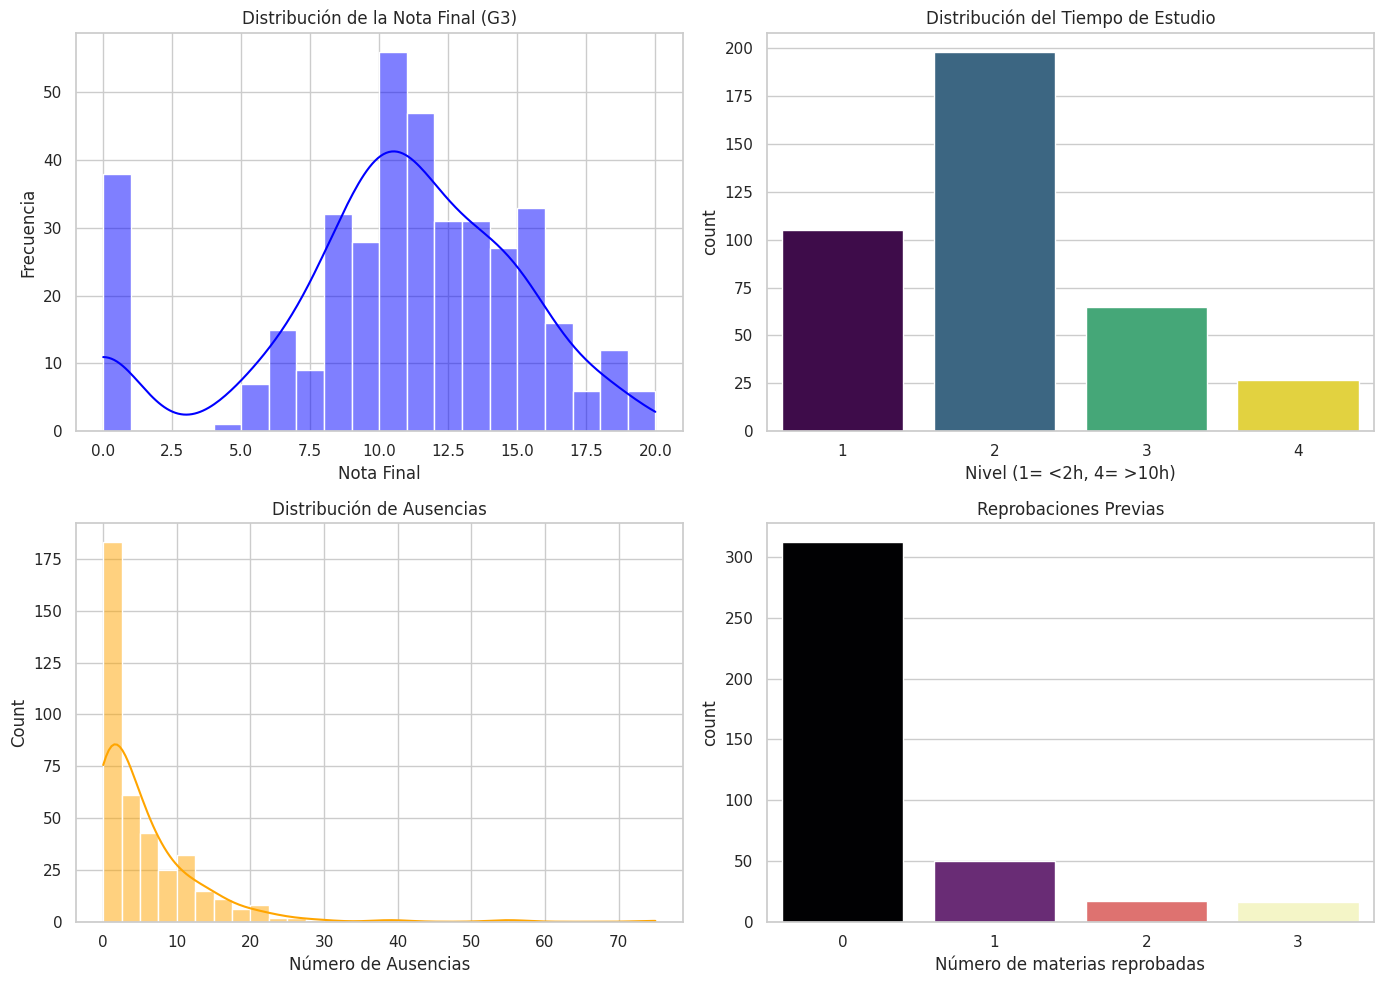

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Distribución de G3
sns.histplot(df['G3'], bins=20, kde=True, ax=axes[0, 0], color='blue')
axes[0, 0].set_title('Distribución de la Nota Final (G3)')
axes[0, 0].set_xlabel('Nota Final')
axes[0, 0].set_ylabel('Frecuencia')

# 2. Tiempo de estudio
sns.countplot(data=df, x='studytime', ax=axes[0, 1], palette='viridis', hue='studytime', legend=False)
axes[0, 1].set_title('Distribución del Tiempo de Estudio')
axes[0, 1].set_xlabel('Nivel (1= <2h, 4= >10h)')

# 3. Ausencias
sns.histplot(df['absences'], bins=30, kde=True, ax=axes[1, 0], color='orange')
axes[1, 0].set_title('Distribución de Ausencias')
axes[1, 0].set_xlabel('Número de Ausencias')

# 4. Reprobaciones previas
sns.countplot(data=df, x='failures', ax=axes[1, 1], palette='magma', hue='failures', legend=False)
axes[1, 1].set_title('Reprobaciones Previas')
axes[1, 1].set_xlabel('Número de materias reprobadas')

plt.tight_layout()
plt.show()

**Análisis de los gráficos:**
1. La nota final (G3) tiene una distribución relativamente normal, pero con un pico atípico en 0, lo que sugiere estudiantes que desertaron o no se presentaron al examen.
2. La mayoría de los estudiantes se concentra en niveles medios de tiempo de estudio (niveles 2 y 3).
3. Las ausencias presentan un sesgo a la derecha: la mayoría tiene pocas ausencias, pero hay casos atípicos con muchas faltas.
4. La mayoría de los estudiantes no tiene reprobaciones previas (failures = 0).


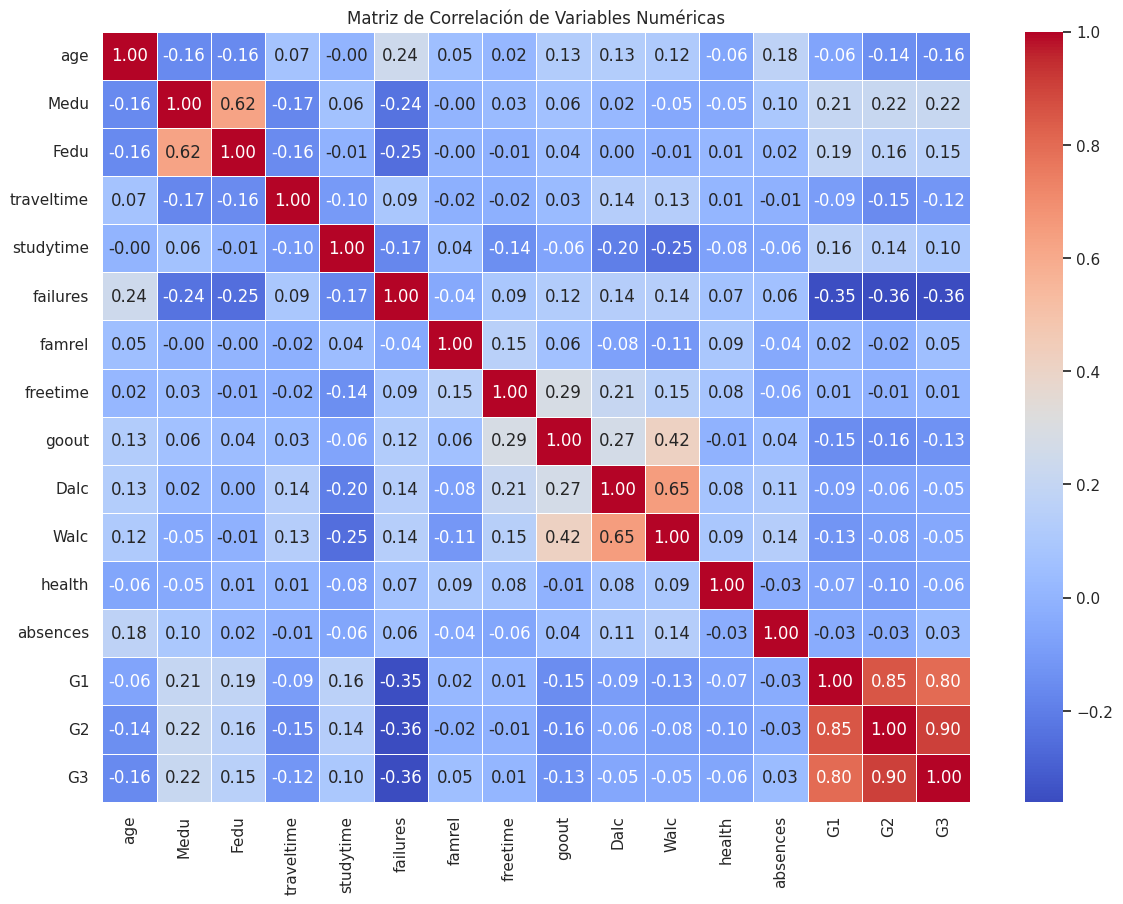

--- CORRELACIÓN CON G3 ---
G3            1.000000
G2            0.904868
G1            0.801468
Medu          0.217147
Fedu          0.152457
studytime     0.097820
famrel        0.051363
absences      0.034247
freetime      0.011307
Walc         -0.051939
Dalc         -0.054660
health       -0.061335
traveltime   -0.117142
goout        -0.132791
age          -0.161579
failures     -0.360415
Name: G3, dtype: float64


In [12]:
# Seleccionar solo variables numéricas
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
df_numerical = df[numerical_cols]

# Calcular matriz de correlación
corr_matrix = df_numerical.corr()

# Gráfico de calor (Heatmap)
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Matriz de Correlación de Variables Numéricas')
plt.show()

# Mostrar las correlaciones más altas con G3
print("--- CORRELACIÓN CON G3 ---")
print(corr_matrix['G3'].sort_values(ascending=False))

**Correlaciones más importantes:**
Las variables más relacionadas con la nota final (G3) son **G2 (0.90)** y **G1 (0.80)**, lo cual es lógico porque son las notas de períodos anteriores. Otras variables con correlación positiva son `Medu` (educación de la madre) y `studytime` (tiempo de estudio). Por otro lado, `failures` (reprobaciones) y `Dalc` (consumo de alcohol) tienen correlación negativa con G3.

In [13]:
print("Hallazgo 1 - Promedio de nota según reprobaciones previas:")
print(df.groupby('failures')['G3'].mean())
print("\n")

print("Hallazgo 2 - Promedio de nota según tiempo de estudio:")
print(df.groupby('studytime')['G3'].mean())
print("\n")

print("Hallazgo 3 - Promedio de nota según consumo de alcohol en fin de semana (Walc):")
print(df.groupby('Walc')['G3'].mean())

Hallazgo 1 - Promedio de nota según reprobaciones previas:
failures
0    11.253205
1     8.120000
2     6.235294
3     5.687500
Name: G3, dtype: float64


Hallazgo 2 - Promedio de nota según tiempo de estudio:
studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64


Hallazgo 3 - Promedio de nota según consumo de alcohol en fin de semana (Walc):
Walc
1    10.735099
2    10.082353
3    10.725000
4     9.686275
5    10.142857
Name: G3, dtype: float64


**Tres hallazgos del EDA:**

1. **Las reprobaciones previas son un fuerte indicador de fracaso:** Los estudiantes que no han reprobado ninguna materia (failures=0) tienen un promedio de **11.25** en su nota final. Sin embargo, aquellos que han reprobado 3 veces bajan drásticamente a un promedio de **5.68**. Esto demuestra que el historial académico es un fuerte predictor del rendimiento.

2. **El tiempo de estudio influye, aunque con matices:** Los que estudian menos de 2 horas (studytime=1) promedian **10.04**, mientras que los que estudian entre 5 y 10 horas (studytime=3) suben a **11.40**. Curiosamente, los que estudian más de 10 horas (studytime=4) promedian **11.25**, lo que sugiere que estudiar en exceso no siempre garantiza mejores notas que un estudio constante y moderado.

3. **El consumo de alcohol afecta el rendimiento:** Los estudiantes con un consumo bajo de alcohol los fines de semana (Walc=1) promedian **10.73**, mientras que aquellos con un consumo muy alto (Walc=4 o 5) ven reducida su nota promedio a **9.68** y **10.14** respectivamente. Esto muestra una tendencia negativa entre el consumo de alcohol y el rendimiento académico.

### Preprocesamiento de datos

- **Faltantes e imputación:** Se revisaron duplicados y nulos, y se introdujo un 5% de valores faltantes al azar en `absences` y `studytime` para simular datos incompletos. Se imputaron las variables numéricas con la mediana porque son discretas y asimétricas (la mediana no se ve afectada por valores altos), y las categóricas con la moda (`most_frequent`) para conservar las categorías más frecuentes.
- **Atípicos en `absences`:** Se evaluaron con la regla del IQR y se conservaron porque corresponden a ausencias reales de los estudiantes y no a errores de carga; eliminarlos quitaría información útil del dataset.
- **Codificación y escalado:** Se aplicó `OneHotEncoder` a las variables categóricas para convertir texto en columnas binarias sin asignar orden numérico artificial, y `StandardScaler` a las numéricas para dejarlas en una misma escala y evitar que variables con rangos mayores dominen sobre otras.
- **División 80/20 y semilla:** Se dividió el dataset en 80% entrenamiento y 20% prueba antes de ajustar el `Pipeline` con `ColumnTransformer` para evitar fuga de datos (*data leakage*), calculando parámetros solo en entrenamiento. Se usó la semilla `202611` por el año y mes del proyecto para mantener la reproducibilidad sin usar `42`.
```

In [17]:
import numpy as np
import pandas as pd

SEED = 202611
rng = np.random.default_rng(SEED)

# Revisar nulos, duplicados y tipos originales
print("Nulos iniciales:", df.isnull().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())

# Simular 5% de valores faltantes al azar en 'absences' y 'studytime'
df_prep = df.copy()
for col in ["absences", "studytime"]:
    n_miss = int(np.floor(0.05 * len(df_prep)))
    idx_miss = rng.choice(df_prep.index, size=n_miss, replace=False)
    df_prep.loc[idx_miss, col] = np.nan

print("Nulos tras simular 5% en absences:", df_prep["absences"].isna().sum())
print("Nulos tras simular 5% en studytime:", df_prep["studytime"].isna().sum())

# Detectar atípicos en 'absences' con la regla IQR
q1 = df_prep["absences"].quantile(0.25)
q3 = df_prep["absences"].quantile(0.75)
iqr = q3 - q1
lim_sup = q3 + 1.5 * iqr
atipicos = df_prep[df_prep["absences"] > lim_sup]
print(f"Q1={q1}, Q3={q3}, IQR={iqr}, Límite superior={lim_sup}, Atípicos={len(atipicos)}")

Nulos iniciales: 0
Filas duplicadas: 0
Nulos tras simular 5% en absences: 19
Nulos tras simular 5% en studytime: 19
Q1=0.0, Q3=8.0, IQR=8.0, Límite superior=20.0, Atípicos=15


Se revisan duplicados y nulos, y se introduce un 5 % de faltantes en absences y studytime para simular datos incompletos usando la semilla 202611 (año y mes del proyecto, evitando 42). Los atípicos de absences detectados por IQR se conservan porque reflejan ausencias reales de estudiantes y eliminarlos perdería información útil.

In [19]:
from sklearn.model_selection import train_test_split

target = "G3"
cols_to_drop = [target, "G1", "G2"]

X = df_prep.drop(columns=cols_to_drop)
y = df_prep[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

print("Tamaño X_train:", X_train.shape)
print("Tamaño X_test:", X_test.shape)

Tamaño X_train: (316, 30)
Tamaño X_test: (79, 30)


Se separa X de la variable objetivo G3 (excluyendo G1 y G2 para evitar fuga directa de notas parciales) y se divide en 80 % entrenamiento y 20 % prueba con semilla 202611 antes de transformar para evitar data leakage y asegurar reproducibilidad.

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category", "string"]).columns.tolist()

num_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

cat_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
X_train_df = pd.DataFrame(X_train_proc, columns=feature_names, index=X_train.index)
X_test_df = pd.DataFrame(X_test_proc, columns=feature_names, index=X_test.index)

print("Forma final X_train_df:", X_train_df.shape)
print("Forma final X_test_df:", X_test_df.shape)
X_train_df.head()

Forma final X_train_df: (316, 39)
Forma final X_test_df: (79, 39)


,num__age,num__Medu,num__Fedu,num__traveltime,num__studytime,num__failures,num__famrel,num__freetime,num__goout,num__Dalc,...,cat__guardian_mother,cat__guardian_other,cat__schoolsup_yes,cat__famsup_yes,cat__paid_yes,cat__activities_yes,cat__nursery_yes,cat__higher_yes,cat__internet_yes,cat__romantic_yes
317,1.001493,1.115265,0.435973,-0.625678,1.119845,-0.445095,0.096664,-0.198478,0.822764,-0.529331,...,1.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
19,-0.549839,1.115265,0.435973,-0.625678,-1.279281,-0.445095,-0.994263,-2.158453,-0.064586,-0.529331,...,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0
106,-1.325506,-0.706046,-0.494889,-0.625678,2.319408,-0.445095,1.187592,-2.158453,-0.951936,-0.529331,...,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0
17,-0.549839,0.204609,0.435973,2.303420,-0.079718,-0.445095,1.187592,-0.198478,-0.951936,-0.529331,...,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0
30,-1.325506,1.115265,1.366836,-0.625678,-0.079718,-0.445095,1.187592,0.781509,-0.951936,1.715887,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0


Se usa Pipeline y ColumnTransformer para imputar numéricas con la mediana (robusta ante valores extremos) y escalarlas con StandardScaler (evitando que rangos mayores dominen), mientras las categóricas se imputan con la moda (most_frequent) y pasan por OneHotEncoder (sin orden numérico artificial), ajustando solo en train para evitar fuga de datos.